# E-commerce Purchase Prediction

## 1. Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

## 2. Load Data

In [2]:
df = pd.read_csv("online_shoppers_intention.csv")
print("Shape:", df.shape)
df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Data Understanding

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [4]:
df["Revenue"].value_counts(normalize=True).round(3) * 100

Revenue
False    84.5
True     15.5
Name: proportion, dtype: float64

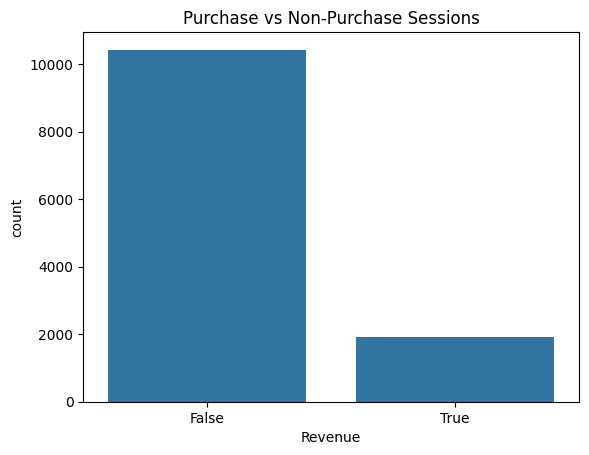

In [5]:
sns.countplot(data=df, x="Revenue")
plt.title("Purchase vs Non-Purchase Sessions")
plt.show()

## 4. Data Cleaning

In [6]:
print("Missing values:\n", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Missing values:
 0
Duplicate rows: 125
Shape after removing duplicates: (12205, 18)


## 5. EDA

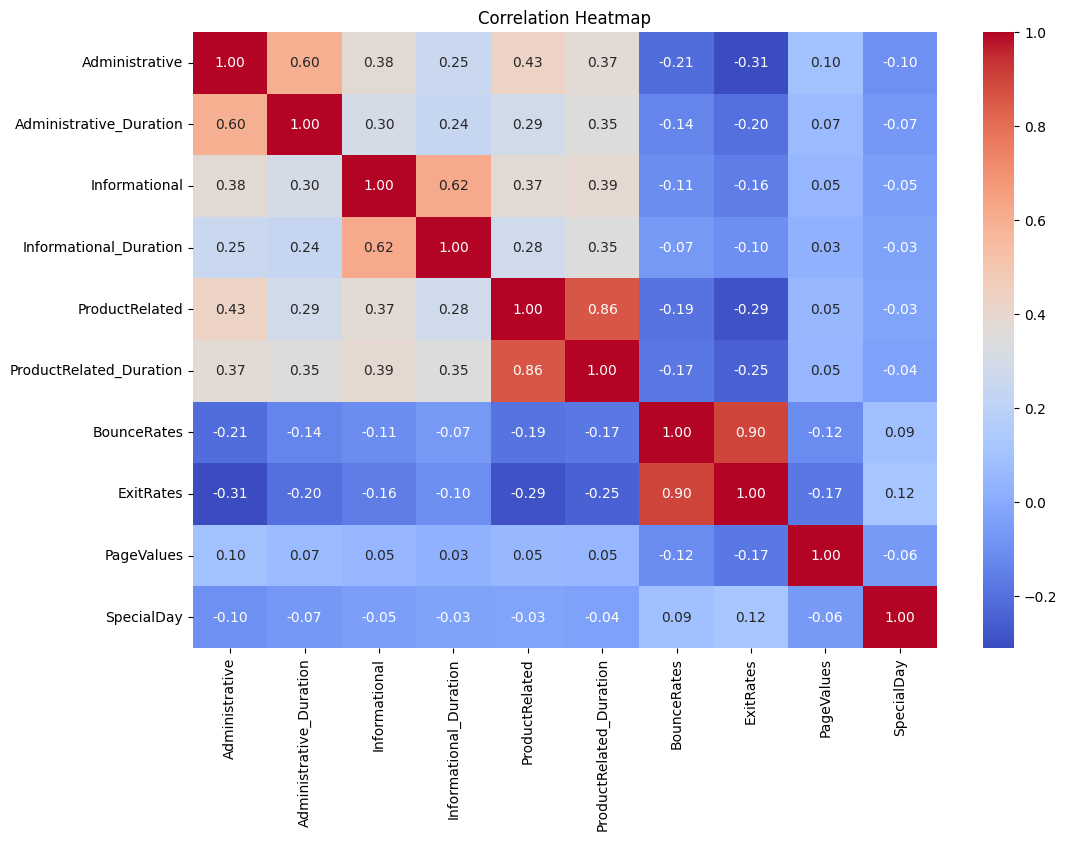

In [7]:
numeric_features = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay"
]

plt.figure(figsize=(12, 8))
sns.heatmap(df[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

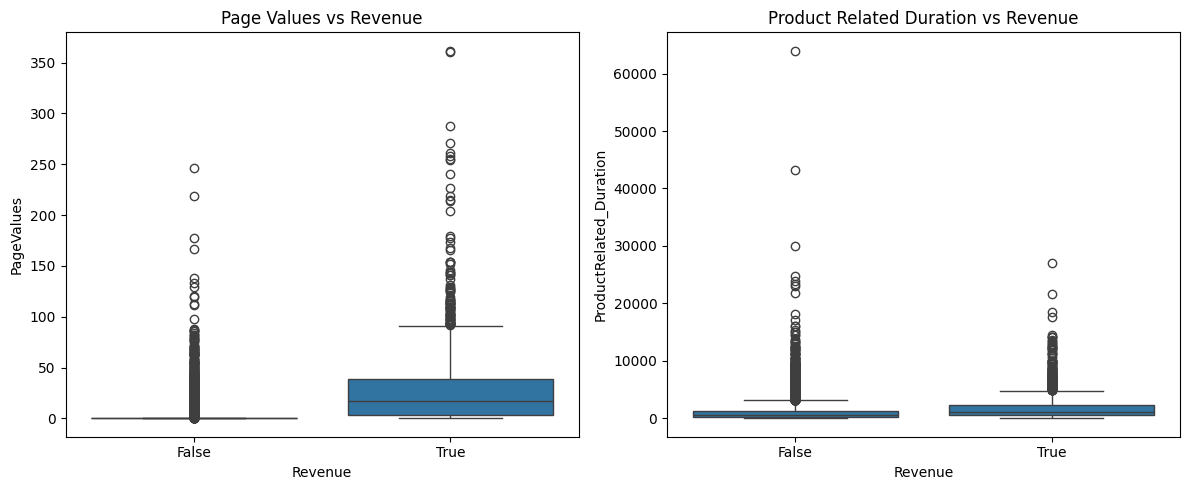

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="Revenue", y="PageValues", ax=axes[0])
axes[0].set_title("Page Values vs Revenue")
sns.boxplot(data=df, x="Revenue", y="ProductRelated_Duration", ax=axes[1])
axes[1].set_title("Product Related Duration vs Revenue")
plt.tight_layout()
plt.show()

## 6. Feature Engineering


In [9]:
df["TotalPages"] = df["Administrative"] + df["Informational"] + df["ProductRelated"]
df["TotalDuration"] = (
    df["Administrative_Duration"] + df["Informational_Duration"] + df["ProductRelated_Duration"]
)
df["AverageTimePerPage"] = np.where(df["TotalPages"] > 0, df["TotalDuration"] / df["TotalPages"], 0)
df["ExitBounceDifference"] = df["ExitRates"] - df["BounceRates"]
df["PageValuePerProductPage"] = np.where(
    df["ProductRelated"] > 0, df["PageValues"] / df["ProductRelated"], 0
)

numeric_features = numeric_features + [
    "TotalPages", "TotalDuration", "AverageTimePerPage",
    "ExitBounceDifference", "PageValuePerProductPage"
]
categorical_features = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]

## 7. Train-Test Split

In [10]:
X = df[numeric_features + categorical_features]
y = df["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Purchase rate in train:", y_train.mean().round(3))

Train: (9764, 22)  Test: (2441, 22)
Purchase rate in train: 0.156


## 8. Preprocessing Pipeline

In [11]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

## 9. Handling Class Imbalance with SMOTE and Model Comparison


In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(random_state=42, n_jobs=-1))
    ]),
    "XGBoost": Pipeline([
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", XGBClassifier(eval_metric="logloss", random_state=42))
    ])
}

cv_results = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    cv_results.append({"Model": name, "Mean F1": scores.mean()})

cv_results = pd.DataFrame(cv_results).sort_values("Mean F1", ascending=False)
cv_results

,Model,Mean F1
1,Random Forest,0.681853
2,XGBoost,0.649328
0,Logistic Regression,0.602130


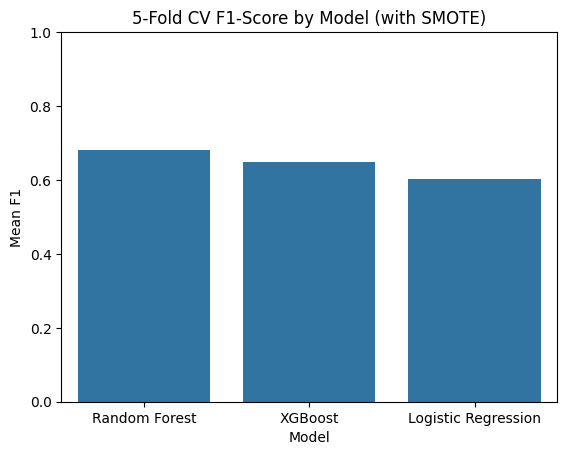

In [13]:
sns.barplot(data=cv_results, x="Model", y="Mean F1")
plt.title("5-Fold CV F1-Score by Model (with SMOTE)")
plt.ylim(0, 1)
plt.show()

## 10. Hyperparameter Tuning (XGBoost + SMOTE)

In [14]:
param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [3, 4],
    "model__learning_rate": [0.05, 0.1]
}

search = GridSearchCV(models["XGBoost"], param_grid, scoring="f1", cv=cv, n_jobs=-1)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV F1-score:", round(search.best_score_, 4))

final_model = search.best_estimator_

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV F1-score: 0.682


## 11. Threshold Tuning

In [15]:
oof_probability = cross_val_predict(
    final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

threshold_results = []
for threshold in np.arange(0.20, 0.81, 0.02):
    pred = (oof_probability >= threshold).astype(int)
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_train, pred),
        "Recall": recall_score(y_train, pred),
        "F1": f1_score(y_train, pred)
    })

threshold_results = pd.DataFrame(threshold_results)
best_threshold = threshold_results.loc[threshold_results["F1"].idxmax(), "Threshold"]
print("Best threshold (by F1):", best_threshold)
threshold_results.sort_values("F1", ascending=False).head()

Best threshold (by F1): 0.46


,Threshold,Precision,Recall,F1
13,0.46,0.632483,0.747706,0.685285
12,0.44,0.625068,0.758191,0.685224
11,0.42,0.617368,0.768676,0.684764
14,0.48,0.641542,0.730668,0.683211
10,0.40,0.608629,0.776540,0.682407


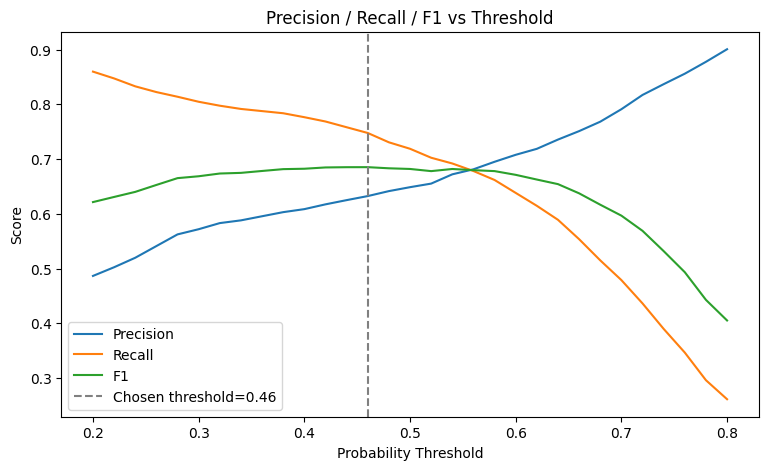

In [16]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_results["Threshold"], threshold_results["Precision"], label="Precision")
plt.plot(threshold_results["Threshold"], threshold_results["Recall"], label="Recall")
plt.plot(threshold_results["Threshold"], threshold_results["F1"], label="F1")
plt.axvline(best_threshold, color="gray", linestyle="--", label=f"Chosen threshold={best_threshold}")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision / Recall / F1 vs Threshold")
plt.legend()
plt.show()

## 12. Final Evaluation on Test Set

In [17]:
y_proba = final_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= best_threshold).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print("Threshold used:", best_threshold)
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Threshold used: 0.46
Accuracy : 0.8964
Precision: 0.6443
Recall   : 0.7539
F1-Score : 0.6948
ROC-AUC  : 0.9318


In [18]:
print(classification_report(y_test, y_pred, target_names=["No Purchase", "Purchase"]))

              precision    recall  f1-score   support

 No Purchase       0.95      0.92      0.94      2059
    Purchase       0.64      0.75      0.69       382

    accuracy                           0.90      2441
   macro avg       0.80      0.84      0.82      2441
weighted avg       0.90      0.90      0.90      2441



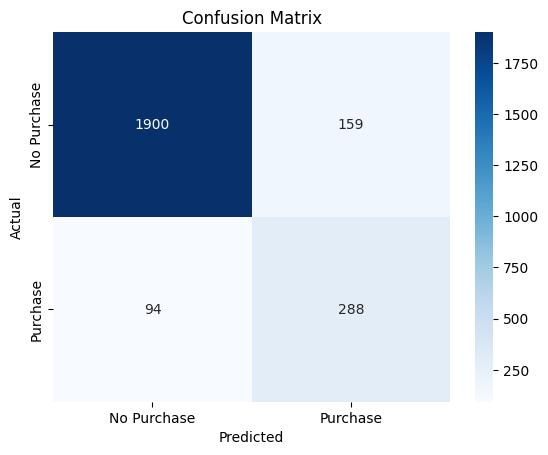

In [19]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Purchase", "Purchase"],
            yticklabels=["No Purchase", "Purchase"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

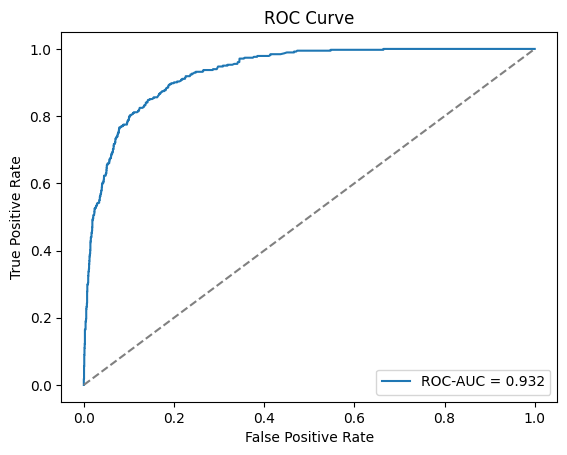

In [20]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

## 13. Feature Importance

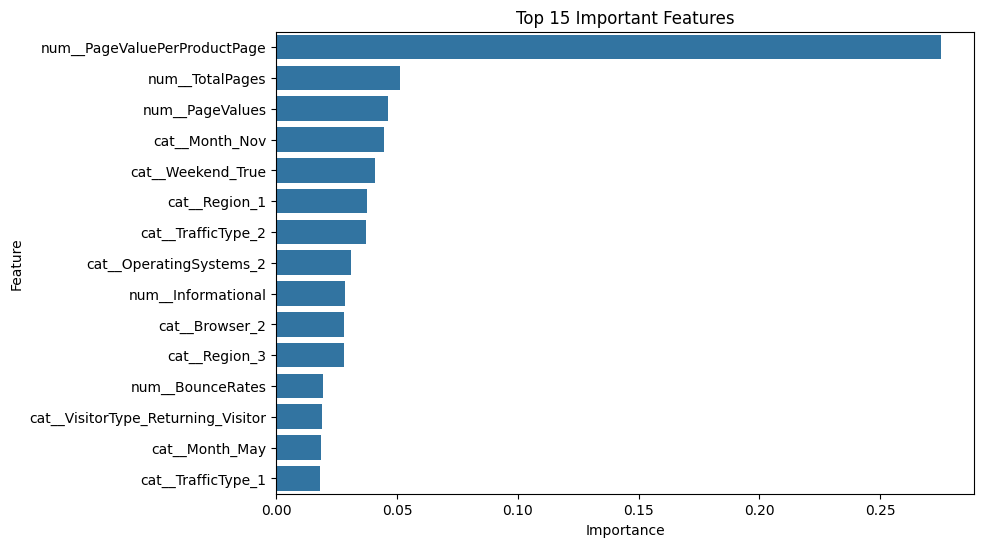

In [21]:
trained_model = final_model.named_steps["model"]
feature_names = final_model.named_steps["prep"].get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_model.feature_importances_
}).sort_values("Importance", ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Top 15 Important Features")
plt.show()